# PM2.5 by hour of the day: Mumbai and Bengaluru (2023)

In this notebook, we show PM2.5 for each hour of 2023 at two CPCB stations.
We use `plot_aqi_radial_hourly` to show the daily cycle in each month and on each day.
The two stations are:

- Powai, Mumbai (MPCB)
- RVCE-Mailasandra, Bengaluru (KSPCB). In 2023, this station had the highest
  median PM2.5 in Bengaluru.

In [1]:
from vayuayan import CPCBHistorical, plot_aqi_radial_hourly, set_theme, sub_index

set_theme()

## Download the data

We download the raw 15-minute values of the two stations with `CPCBHistorical.raw_readings`.
All times are in Indian Standard Time (IST).

In [2]:
raw = CPCBHistorical().raw_readings(["site_5112", "site_5678"], 2023, ["PM2.5"])
raw["station_name"].value_counts()

station_name
Powai, Mumbai - MPCB                   32565
RVCE-Mailasandra, Bengaluru - KSPCB    24647
Name: count, dtype: int64

## Remove the suspect values

From 30 July to 1 September, the Bengaluru station recorded a smaller number of values than
usual. The highest value was 923 µg/m³, approximately three times the values in the
weeks before and after. Rain removes particles from the air in the monsoon. Thus,
we think that an instrument fault caused these high values. We remove these weeks.

In [3]:
suspect = (
    (raw["station_id"] == "site_5678")
    & (raw["timestamp"] >= "2023-07-30")
    & (raw["timestamp"] < "2023-09-02")
)
raw = raw[~suspect]

## Calculate the hourly sub-index

We calculate the mean of the four 15-minute values in each hour. Then we use
`sub_index` to change each hourly mean to the CPCB PM2.5 sub-index. CPCB defines
the sub-index for a 24-hour mean. Thus, the hourly sub-index is not an official
AQI. We use it to put each hour on the scale of the AQI categories.

In [4]:
hourly = (
    raw.assign(timestamp=raw["timestamp"].dt.floor("h"))
    .groupby(["station_name", "timestamp"], as_index=False)["value"]
    .mean()
)
hourly["value"] = [sub_index("PM2.5", c) for c in hourly["value"]]
hourly["city"] = hourly["station_name"].str.replace(r" - .*", "", regex=True)
hourly.head()

,station_name,timestamp,value,city
0,"Powai, Mumbai - MPCB",2023-01-01 00:00:00,87.585259,"Powai, Mumbai"
1,"Powai, Mumbai - MPCB",2023-01-01 01:00:00,119.093103,"Powai, Mumbai"
2,"Powai, Mumbai - MPCB",2023-01-01 02:00:00,306.744302,"Powai, Mumbai"
3,"Powai, Mumbai - MPCB",2023-01-01 03:00:00,200.765000,"Powai, Mumbai"
4,"Powai, Mumbai - MPCB",2023-01-01 04:00:00,195.587672,"Powai, Mumbai"


## Show the daily cycle in each month

If you do not set rings, `plot_aqi_radial_hourly` shows one ring for each month. January is at the
center and midnight is at the top.

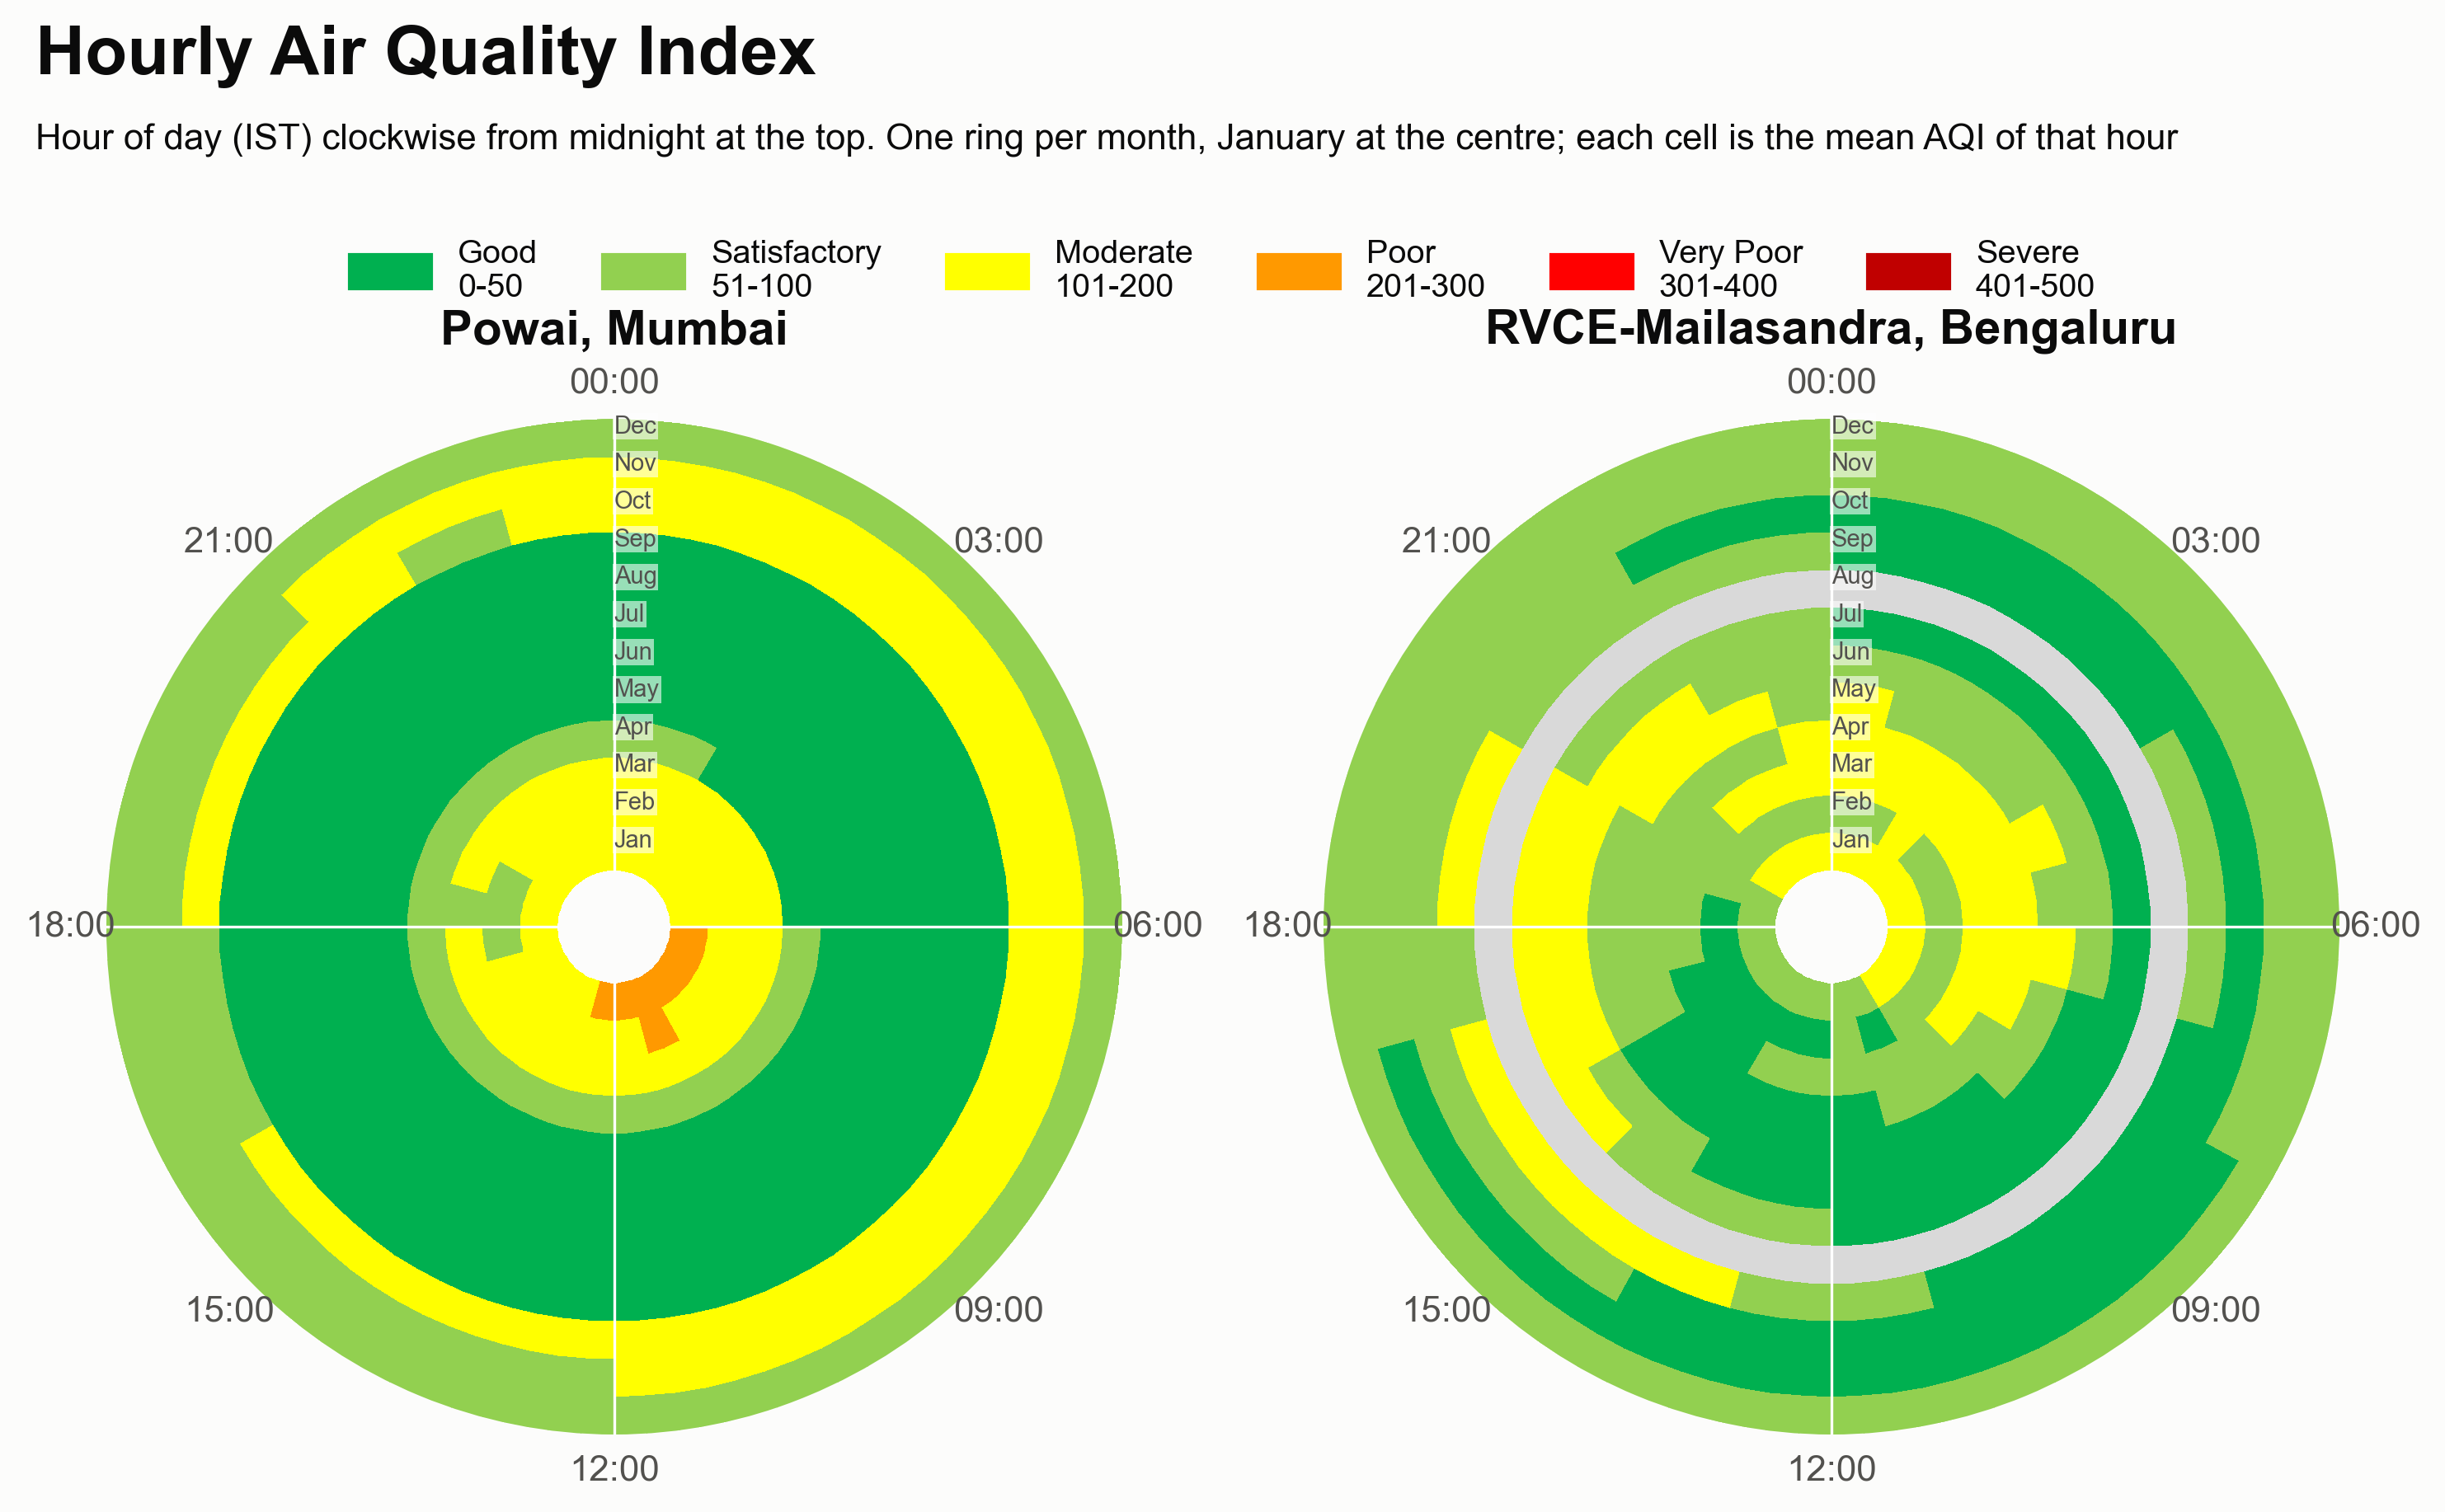

In [5]:
plot_aqi_radial_hourly(hourly)

We see these results:

- In Powai, PM2.5 is highest from October to March. The mean is 87 µg/m³ in
  January. From May to September, the mean is 13 to 20 µg/m³ and all hours are
  Good.
- In winter, PM2.5 in Powai is highest at 09:00 to 10:00. In January, all hours
  from 06:00 to 12:00 are Poor. At night, a thin layer of cold air stays near
  the ground. Morning traffic adds particles to this layer. When the sun heats
  the ground, the layer becomes thicker and the particles mix into more air.
- In Bengaluru, the change between the seasons is smaller. The monthly mean is
  23 µg/m³ in October and 60 µg/m³ in January. No month is Good at all hours.
- In Bengaluru from December to February, PM2.5 stays high for most of the
  night. The mean is 54 to 59 µg/m³ from 21:00 to 08:00 and 32 to 36 µg/m³ from
  10:00 to 15:00.

## Show one ring for each day

Set `rings="day"` to show one ring for each date. Then we can see
events of one or two days. For example, Diwali was on 12 November 2023.

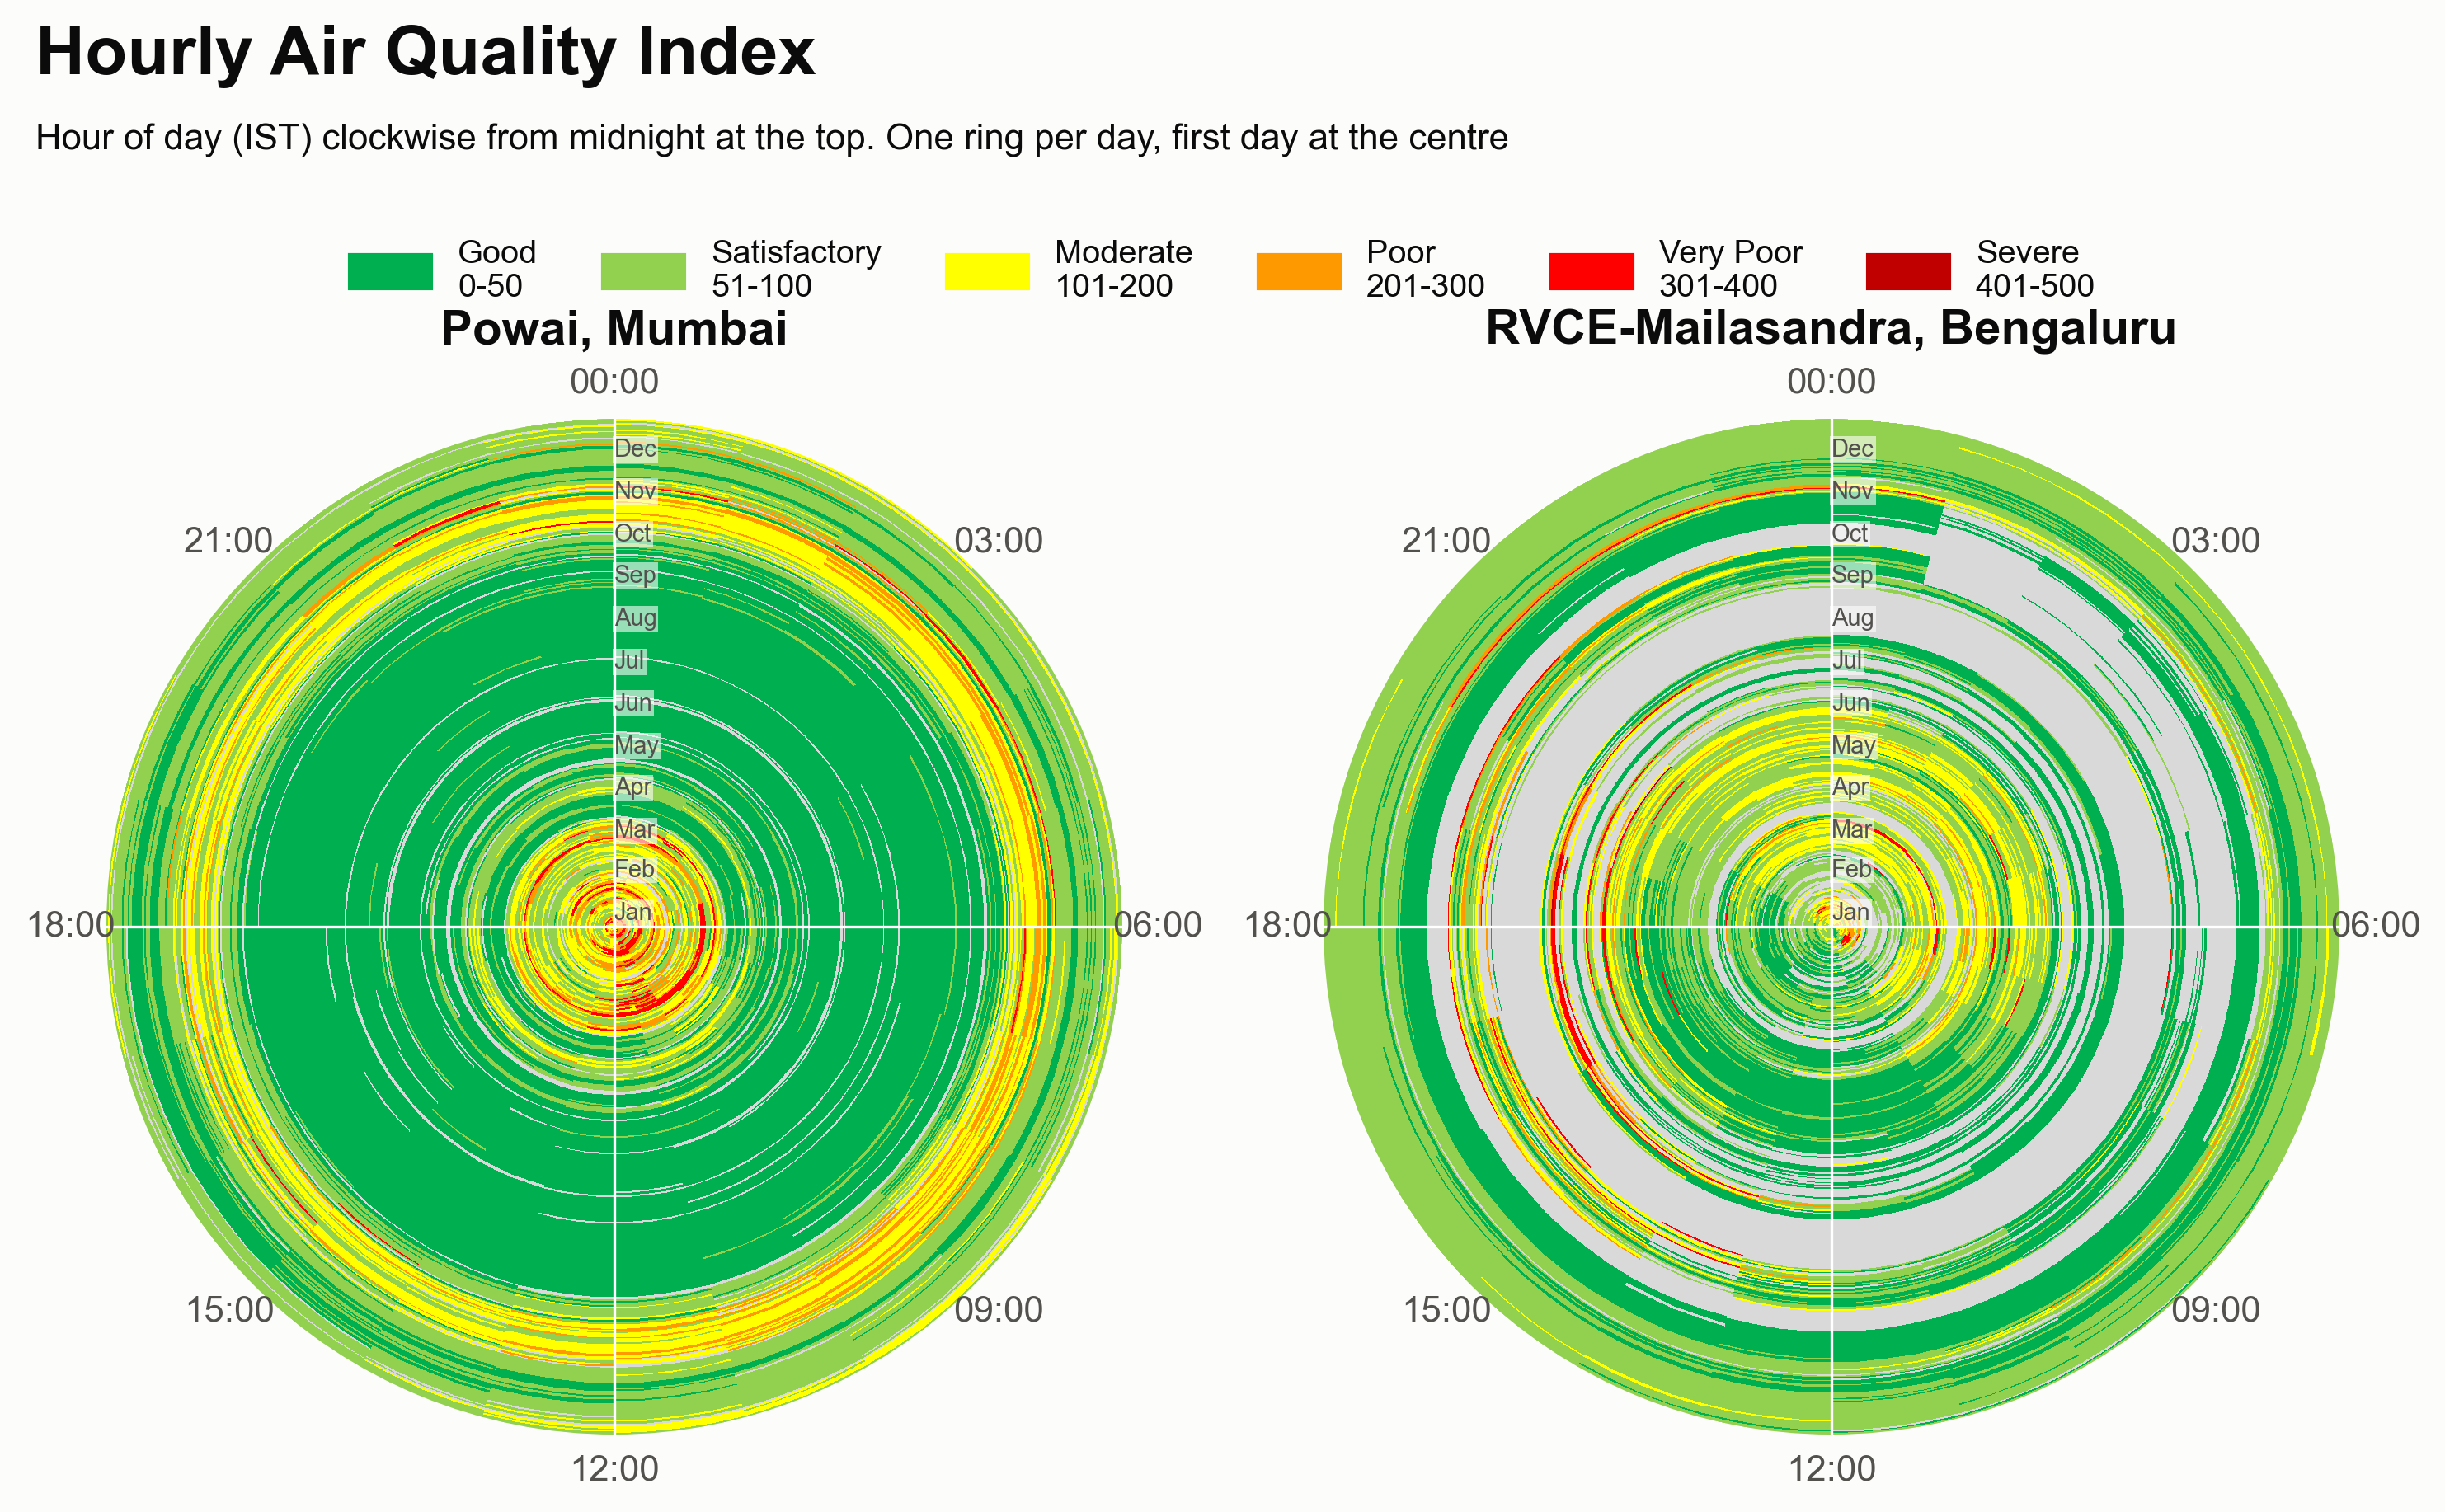

In [6]:
plot_aqi_radial_hourly(hourly, rings="day")

At the two stations, the mean PM2.5 from 19:00 to 02:00 was 35 to 53 µg/m³ on
8 to 10 November. On the nights of 12 and 13 November, the mean was 103 to
127 µg/m³.